# Estimating Peat Subsidence with BLUE

We start by assuming a **linear model** that describes the movement with an **offset and a linear trend**, and estimate these with Best Linear Unbiased Estimation (BLUE).

## Data

We have two independent measurement techniques that observe the **same parcel**:

| | InSAR | Extensometer |
|---|---|---|
| What is measured | Average height change of the **whole parcel** (radar satellite) | Height change at **one point** in the parcel (instrument in a borehole) |
| Sampling | every 6 days (some epochs missing due to lack of coherence) | daily |
| Precision | $\sigma_{\text{InSAR}} = 3$ mm | $\sigma_{\text{ext}} = 8$ mm |

For both datasets you may assume that the observations are **normally distributed and independent**, with the standard deviations given in the table.

In addition, the file `weather.csv` contains daily precipitation and evapotranspiration for the area. We will only use it to help interpret the results this week; next week it becomes part of the model.

All files are in the folder `data/`. Every file has a column `Day`, which is the number of days since 1 January 2019 (the first day of the weather record, which starts one year before the observations). You can use it to link observations to the weather.


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.stats.distributions import chi2

np.set_printoptions(precision=3)

## Part 1

Download and read the data

In [14]:
import os
from urllib.request import urlretrieve

def findfile(fname):
    if not os.path.isfile(fname):
        print(f'Downloading {fname}...')
        urlretrieve('https://github.com/TUDelft-MUDE/source-files/raw/main/file/GA1.7/'+fname, fname)

findfile('insar_observations.csv')
findfile('extensometer_observations.csv')
findfile('weather.csv')

In [16]:
insar = pd.read_csv('insar_observations.csv')
ext = pd.read_csv('extensometer_observations.csv')
weather = pd.read_csv('weather.csv')

dates_insar = pd.to_datetime(insar['Dates'])
day_insar = insar['Day'].to_numpy()
y_insar = insar['Observations[m]'].to_numpy() * 1000      # mm

dates_ext = pd.to_datetime(ext['Dates'])
day_ext = ext['Day'].to_numpy()
y_ext = ext['Observations[m]'].to_numpy() * 1000          # mm

dates_weather = pd.to_datetime(weather['Dates'])
P = weather['Precipitation[mm]'].to_numpy()                # mm/day
E = weather['Evapotranspiration[mm]'].to_numpy()           # mm/day


sigma_insar = 3   # mm
sigma_ext = 8     # mm

> **Task 1.1:**
>
> Investigate the two displacement datasets: print some summary statistics (number of observations, first and last date, minimum, maximum, ...) and plot both time series in one figure. Also make a plot of the precipitation (P) and evapotranspiration (E).
>
> Describe the two datasets in your own words. Consider at least:
> 1. the differences in sampling and precision;
> 2. what each technique physically observes (what could be the reason the plots of the two measurements are slightly different);
> 3. the patterns you see in the time series.
>
>*Note down your findings*

In [ ]:
# Print summary statistics of both displacement datasets
### YOUR CODE LINES HERE

# Plot both time series in one figure, and the weather data in a second figure
### YOUR CODE LINES HERE


## Part 2: Functional model

We start with the simplest model for the height change $d$ at time $t$: an offset and a constant velocity,

$$
d(t) = d_0 + v\, t,
$$

where $d_0$ [mm] is the relative surface height at $t=0$ and $v$ [mm/year] is the velocity. We define $t$ in **years since 1 January 2020** (the first observation epoch), so that $d_0$ refers to the same moment for both datasets.

We fit this model **separately** to the InSAR data and to the extensometer data.

> **Task 2.1:**
>
> Compute the time $t$ in years for both datasets and set up the design matrices `A_insar` and `A_ext`.
>
> *Hint:* the column `Day` is the number of days since 1 January 2019; 1 January 2020(first day of extensometer and InSAR observations) is day 365. Use 365.25 days per year.


In [5]:
day_0 = 365

t_insar = (day_insar - day_0) / 365.25
t_ext = (day_ext - day_0) / 365.25

A_insar = np.column_stack((np.ones(len(t_insar)), t_insar))
A_ext = np.column_stack((np.ones(len(t_ext)), t_ext))

print('First 3 rows of A_insar:\n', A_insar[:3])
print('First 3 rows of A_ext:\n', A_ext[:3])


First 3 rows of A_insar:
 [[1.    0.   ]
 [1.    0.016]
 [1.    0.033]]
First 3 rows of A_ext:
 [[1.    0.   ]
 [1.    0.003]
 [1.    0.005]]


> **Task 2.2:**
>
> Answer the following questions (use the code cell to compute the numbers):
> 1. Write down the unknown parameters of the functional model, and their units
> 2. How many observations $m$ and unknowns $n$ are there for each dataset?

*Make sure to note down your findings with pen and paper*

In [6]:

# Number of observations and unknowns

m_insar, n_insar = A_insar.shape
m_ext, n_ext = A_ext.shape

print("InSAR:")
print("Number of observations (m):", m_insar)
print("Number of unknowns (n):", n_insar)

print("\nExtensometer:")
print("Number of observations (m):", m_ext)
print("Number of unknowns (n):", n_ext)


InSAR:
Number of observations (m): 145
Number of unknowns (n): 2

Extensometer:
Number of observations (m): 1461
Number of unknowns (n): 2


## Part 3: Stochastic model

The stochastic model describes the precision of the observations with the covariance matrix $\Sigma_Y$.

> **Task 3.1:**
>
> Set up the covariance matrices `Sigma_Y_insar` and `Sigma_Y_ext`.
>
> Print the shapes of the covariance matrices
>
> Print the first 3x3 entries
>


In [7]:

Sigma_Y_insar = sigma_insar**2 * np.eye(len(y_insar))
Sigma_Y_ext = sigma_ext**2 * np.eye(len(y_ext))

print('shape of Sigma_Y_insar:', Sigma_Y_insar.shape)
print('shape of Sigma_Y_ext:', Sigma_Y_ext.shape)

print('Sigma_Y_insar (first 3x3):\n', Sigma_Y_insar[:3, :3])
print('Sigma_Y_ext (first 3x3):\n', Sigma_Y_ext[:3, :3])

shape of Sigma_Y_insar: (145, 145)
shape of Sigma_Y_ext: (1461, 1461)
Sigma_Y_insar (first 3x3):
 [[9. 0. 0.]
 [0. 9. 0.]
 [0. 0. 9.]]
Sigma_Y_ext (first 3x3):
 [[64.  0.  0.]
 [ 0. 64.  0.]
 [ 0.  0. 64.]]


> **Task 3.2:**

> 1. What is the dimension of both $\Sigma_Y$ matrices?
> 2. What value is on the diagonal for both $\Sigma_Y$ matrices? 
>
*note down your findings with pen and paper*

## Part 4: Apply Best Linear Unbiased Estimation



> **Task 4.1:**
>
> Complete the function `BLUE` below and use it to estimate the unknown parameters and the parameter covariance matrix for both datasets.
> 1. print the unknown parameters
> 2. print the covariance matrix of the parameters
>
>*note down the your computations and outcome on paper*


In [8]:
def BLUE(A, y, Sigma_Y):
    '''Best Linear Unbiased Estimator.

    Input:  A, y, Sigma_Y
    Output: xhat, Sigma_X
    '''

    # Inverse of observation covariance matrix
    Sigma_Y_inv = np.linalg.inv(Sigma_Y)

    # Covariance matrix of estimated parameters
    Sigma_X = np.linalg.inv(A.T @ Sigma_Y_inv @ A)

    # Estimate unknown parameters
    xhat = Sigma_X @ A.T @ Sigma_Y_inv @ y

    return xhat, Sigma_X


# Apply BLUE to both datasets
xhat_insar, Sigma_X_insar = BLUE(A_insar, y_insar, Sigma_Y_insar)
xhat_ext, Sigma_X_ext = BLUE(A_ext, y_ext, Sigma_Y_ext)

# Print estimated parameters and covariance matrices
print("=== InSAR ===")
print("Estimated parameters [d0, v]:", xhat_insar)
print("Covariance matrix:\n", Sigma_X_insar)

print("\n=== Extensometer ===")
print("Estimated parameters [d0, v]:", xhat_ext)
print("Covariance matrix:\n", Sigma_X_ext)


=== InSAR ===
Estimated parameters [d0, v]: [ 6.003 -5.369]
Covariance matrix:
 [[ 0.253 -0.094]
 [-0.094  0.046]]

=== Extensometer ===
Estimated parameters [d0, v]: [ 2.368 -7.947]
Covariance matrix:
 [[ 0.175 -0.066]
 [-0.066  0.033]]


## Part 5: Model predictions and residuals

Compute the estimated observations $\hat{Y}$ and the residuals $\hat{\epsilon}$.


> **Task 5.1:**
>
> Complete the function `get_results` to compute $\hat{Y}$, $\hat{\epsilon}$ and the standard deviations of both.


In [23]:

def get_results(A, y, Sigma_Y, xhat, Sigma_X):

    # Predicted observations
    yhat = A @ xhat

    # Residuals
    ehat = y - yhat

    # Covariance matrix of predicted observations
    Sigma_yhat = A @ Sigma_X @ A.T

    # Covariance matrix of residuals
    Sigma_ehat = Sigma_Y - Sigma_yhat

    # Standard deviations
    std_yhat = np.sqrt(np.maximum(np.diag(Sigma_yhat), 0))
    std_ehat = np.sqrt(np.maximum(np.diag(Sigma_ehat), 0))

    return yhat, ehat, std_yhat, std_ehat


# Apply to InSAR
yhat_insar, ehat_insar, std_yhat_insar, std_ehat_insar = get_results(
    A_insar, y_insar, Sigma_Y_insar, xhat_insar, Sigma_X_insar
)

# Apply to extensometer
yhat_ext, ehat_ext, std_yhat_ext, std_ehat_ext = get_results(
    A_ext, y_ext, Sigma_Y_ext, xhat_ext, Sigma_X_ext
)


> **Task 5.2:**
>
> Complete the function `plot_results` below by computing the 98% confidence intervals of $\hat{Y}$ and $\hat{\epsilon}$. 


In [ ]:
def plot_results(name, dates, y, yhat, ehat, std_yhat, std_ehat, sigma, alpha):
    '''Plot observations + fitted model, residuals and a histogram of the normalized residuals.'''
     # Confidence interval multiplier
    k98 = norm.ppf(1 - alpha / 2)

    # Confidence interval half-widths
    CI_y = k98 * sigma
    CI_e = k98 * std_ehat
    CI_yhat = k98 * std_yhat

    CI_label = f'{100 * (1 - alpha):.0f}% confidence region'
    fig = plt.figure(figsize=(14, 8))
    ax1 = plt.subplot2grid((2, 3), (0, 0), colspan=3)
    ax2 = plt.subplot2grid((2, 3), (1, 0), colspan=2)
    ax3 = plt.subplot2grid((2, 3), (1, 2))

    ax1.plot(dates, y, '.', color='k', ms=3, label='observations')
    ax1.plot(dates, yhat, color='tab:red', label='fitted model')
    ax1.fill_between(dates, yhat - CI_yhat, yhat + CI_yhat,
                     color='tab:red', alpha=0.3, label=f'CI yhat {100 * (1 - alpha):.0f}%')

    ax1.set_xlim(dates.iloc[0], dates.iloc[-1])
    ax1.set_ylabel('displacement [mm]')
    ax1.set_title(f'{name}: observations and fitted model')
    ax1.legend(loc='lower left')

    ax2.plot(dates, ehat, '.', color='k', ms=3)
    ax2.fill_between(dates, -CI_e, CI_e, color='tab:red', alpha=0.2,
                     label=f'CI ehat {100 * (1 - alpha):.0f}%')
 
    ax2.set_xlim(dates.iloc[0], dates.iloc[-1])
    ax2.set_ylabel('residual [mm]')
    ax2.set_title('residuals')
    ax2.legend(loc='lower left')

    ax3.hist(ehat / sigma, bins=30, density=True, color='lightgrey', edgecolor='k')
    xx = np.linspace(-4, 4, 200)
    ax3.plot(xx, norm.pdf(xx), color='tab:red', label='N(0,1)')
    ax3.set_xlabel('residual / sigma [-]')
    ax3.set_title('normalized residuals')
    ax3.legend()
    plt.tight_layout()
    plt.show()

    print(f'{name}: mean residual = {ehat.mean():.2f} mm, std residual = {ehat.std():.2f} mm '
          f'(sigma = {sigma} mm)')


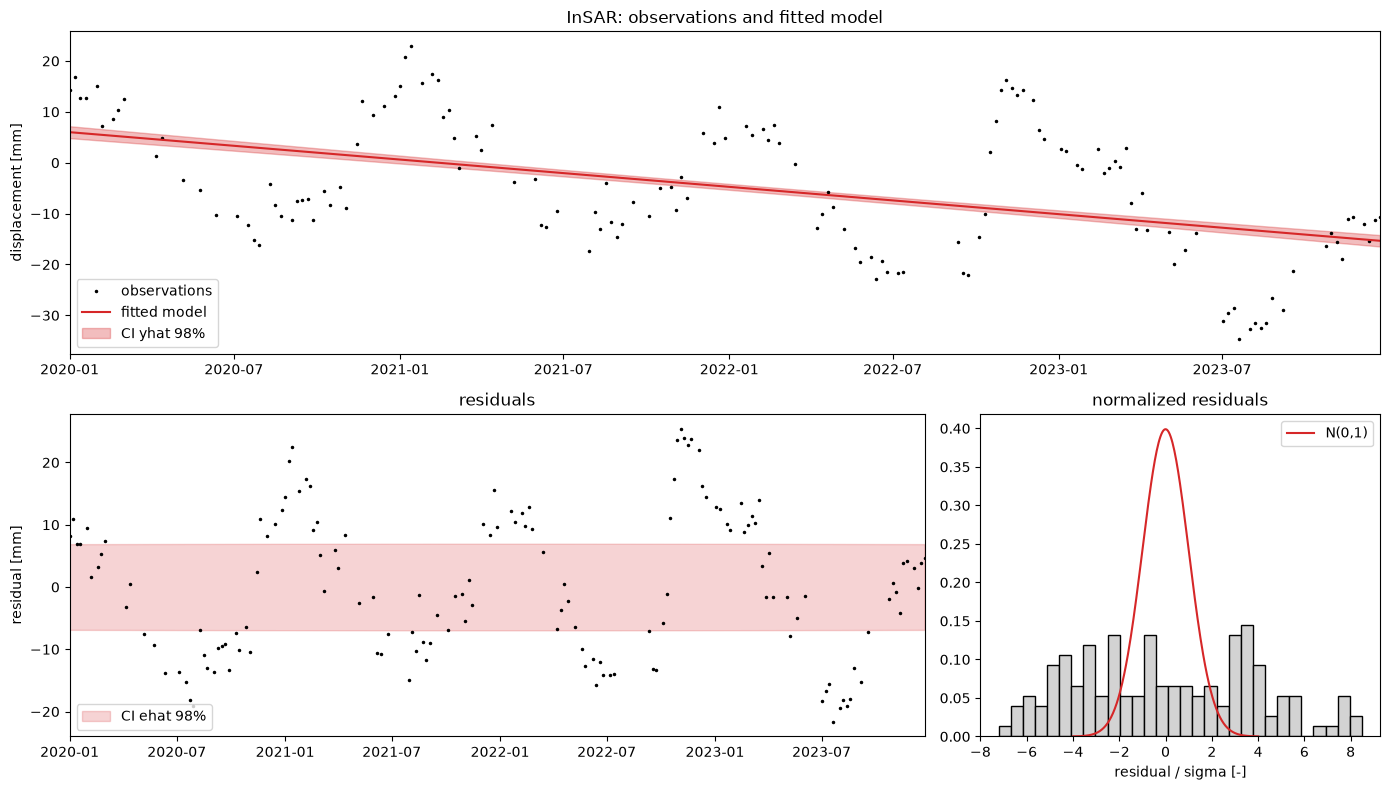

InSAR: mean residual = -0.00 mm, std residual = 11.50 mm (sigma = 3 mm)


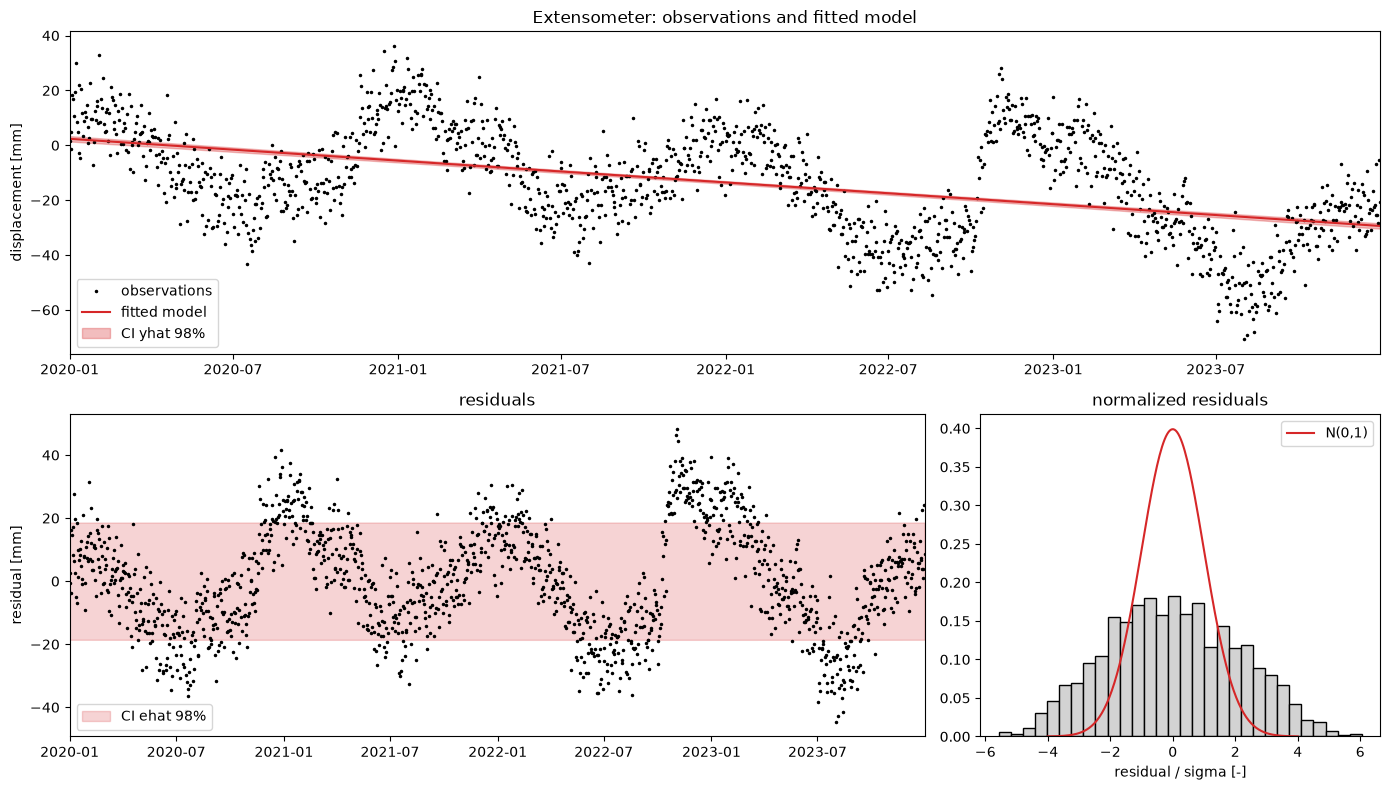

Extensometer: mean residual = 0.00 mm, std residual = 16.86 mm (sigma = 8 mm)


In [25]:
plot_results('InSAR', dates_insar, y_insar, yhat_insar, ehat_insar,
             std_yhat_insar, std_ehat_insar, sigma_insar, alpha=0.02)
plot_results('Extensometer', dates_ext, y_ext, yhat_ext, ehat_ext,
             std_yhat_ext, std_ehat_ext, sigma_ext, alpha=0.02)

> **Task 5.3:**
>
> Write down your observations for each figure: the graphs of $\hat{y}$ and $\hat{e}$ and the distribution of the normalized residuals. 


## Part 6: A model driven by the weather (Model 2)

In this part we build a model that uses the weather data to explain the surface movement, while keeping it **linear**, so that we can still use BLUE.

Lets check out the weather data (we loaded this already in the beginning of the notebook)


### What is in `weather.csv`?

The file contains one row for **every day** from 1 January 2019 to 31 December 2023. The weather starts one year *before* the first observation (1 January 2020). We explain why below.

| Column | Unit | Meaning |
|---|---|---|
| `Dates` | – | calendar date |
| `Day` | days | number of days since 1 January 2019 (day 0) |
| `Precipitation[mm]` | mm/day | precipitation $P$: water that comes **in** (rain) |
| `Evapotranspiration[mm]` | mm/day | evapotranspiration $E$: water that goes **out** (evaporation from the soil + transpiration by the grass) |
| `Dry[-]` | – | 1 if the day is **dry**, 0 if it is wet (definition below) |
| `DryDays[days]` | days | $D(t)$: the **number of dry days** counted from the start of the file up to and including that day |

The difference $P - E$ [mm/day] is the **net water input** of the parcel. Positive means the parcel gets wetter that day; negative means it dries out.

`Day` shows the number of days since 1 January 2019 (starts at 0). So for an observation on day `Day`, the weather on that day is simply `P[Day]`, `D[Day]`, etc.


## Two processes, two weather variables

Lets introduce two processes that we think will affect the movement of peat ground. We describe each of them with a variable computed from the weather file.

**1. Irreversible subsidence: the dry-day counter $D(t)$**

Peat only oxidises when it is **dry**, so the ground only goes down on dry days. A day is **dry** when the net water input over the last few days (including that day) is zero or negative.

$D(t)$ is the number of dry days up to day $t$. It goes up by 1 on a dry day and stays the same on a wet day. You can find it in the column `DryDays` of the weather file.

The irreversible subsidence is then:

$$x_I \, D(t)$$

where $x_I$ is the subsidence per dry day [mm/day]. This replaces the $v\,t$ term of the linear trend.


**2. Reversible motion: the water surplus $S_\tau(t)$**

The soil swells when it gets wetter and shrinks when it dries out. How wet it is depends on today's weather and also on the days and weeks before: the soil has a *memory*. We model this as a **leaky bucket**. Each day the net input $P - E$ is added, and part of the old content leaks away:

$$
S_i = e^{-1/\tau}\, S_{i-1} + (P_i - E_i)
$$

$S_i$ is the **water surplus** [mm] on day $i$. Because each day depends on the day before, you compute it day by day. Start with an empty bucket on the first day of the weather record. We write it as $S_\tau(t)$ because it depends on $\tau$.

$\tau$ [days] is the soil's memory. Each day the bucket keeps a fraction $e^{-1/\tau}$ of its content. For example, $\tau = 10$ gives $e^{-1/10} \approx 0.90$, so about 10% leaks away each day.
- Small $\tau$: the soil reacts fast and forgets fast.
- Large $\tau$: the soil reacts slowly and remembers longer.

The reversible motion is then:

$$k \, S_\tau(t)$$

where $k$ [-] is a scaling factor.

**Why does the weather data start one year earlier?** We start the bucket empty on 1 January 2019, which is not the real state of the soil. After a year, the effect of that starting value is negligible. The dry-day counter also needs the previous days (we computed this already for you in `DryDays`). This first year is called the *spin-up* period.


### The new functional model

Combining both processes gives

$$
d(t) = d_0 + x_I \, D(t) + k \, S_\tau(t) .
$$

In this assignment we  **fix** $\tau = 10$ days. Then $D(t)$ and $S_{10}(t)$ are known numbers for every day, and the three unknowns $d_0$, $x_I$ and $k$.


> **Task 6.1:**
>
> 1. Load the dry-day counter $D$ from the column `DryDays[days]` of the weather file.
> 2. Complete the function `water_surplus` below and compute the water surplus $S$ with $\tau = 10$ days for every day of the weather record.
> 3. Plot both $D(t)$ and $S_{10}(t)$ for every day of the weather record
>
> Then run the cell after it to plot $S$ and $D$.


In [ ]:
D = ### YOUR CODE HERE ###

def water_surplus(P, E, tau):
    '''Leaky-bucket water surplus S [mm] for every day of the weather record.'''
    a = np.exp(-1 / tau)
    S = np.zeros(len(P))
    S_previous = 0.0
    for i in range(len(P)):
        S[i] = ### YOUR CODE HERE ###
        S_previous = S[i]
    return S

tau = 10   # days (fixed)
S = water_surplus(P, E, tau)


In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(dates_weather, S)
ax[0].set_ylabel('S [mm]')
ax[0].set_title(f'Water surplus (tau = {tau} days)')
ax[1].plot(dates_weather, D, color='tab:orange')
ax[1].set_ylabel('D [days]')
ax[1].set_title('Number of dry days')
for a in ax:
    a.axvline(dates_insar.iloc[0], color='k', ls='--', lw=1, label='First observation')   # first observation
for a in ax:
    a.legend()
plt.tight_layout()


> **Task 6.2:**
>
> Describe the behavior of $S$ and $D$ over the year. (make a sketch of the plots)



> **Task 6.3:**
>
> Set up the design matrices `A2_insar` and `A2_ext` for the new model and estimate the unknowns with your `BLUE` function. Use the column `Day` (same as you did for your design matrix for model 1) to pick the values of $D$ and $S$ on the observation days.


In [ ]:
A2_insar = ### YOUR CODE HERE ###
A2_ext = ### YOUR CODE HERE ###

xhat2_insar, Sigma_X2_insar = ### YOUR CODE HERE ###
xhat2_ext, Sigma_X2_ext = ### YOUR CODE HERE ###


> **Task 6.4:**
>
> Compute the adjusted observations and residuals of the new model by calling your `get_results` function, plot them with `plot_results` (plot again the 98% confidence level)


In [ ]:
##YOUR CODE HERE##


> **Task 6.5:**
>
> 1. Interpret the estimated parameters. Convert $x_I$ to mm/year (compute how many days per year on average the parcel has) and compare it with the velocity $v$ from Part 4 (model 1).
> 2. Compare the estimated observations and residuals with those of model 1, compare the figures. 
>
>*Note down your findings with pen and paper*


In [ ]:
# average number of dry days per year during the observation period (2020-2023)
first_day, last_day = ### YOUR CODE HERE ###
years = ### YOUR CODE HERE ###
N_dry = ### YOUR CODE HERE ###
print(f'average number of dry days per year: {N_dry:.1f}')

#convert x_I from mm/day to v_I mm/year to compare with velocity estimates from the model 1
### YOUR CODE LINES HERE


*Do a double check and make sure you wrote all your findings down with pen and paper, so that you can discuss or refer to them when answering the questions in the report*

> By `Isabel Slingerland`, Delft University of Technology. CC BY 4.0, more info [on the Credits page of Workbook](https://mude.citg.tudelft.nl/workbook-2026/credits.html).
